# TUẦN 2: EXPLORATORY DATA ANALYSIS (EDA) & DATA QUALITY REVIEW
**Đề tài:** Phân tích cảm xúc đánh giá khách hàng (Shopee Reviews) bằng Deep Learning  
**Học phần:** Artificial Intelligence (VNUK Capstone 2025)  
**Nhóm thực hiện:** Thái Bảo (Leader), Tuấn Kiệt, Đức Minh, Đình Hiếu, Huy Hoàng

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Đọc dữ liệu từ file raw
data_path = os.path.join("..", "data", "raw", "shopee_reviews.csv")
df = pd.read_csv(data_path)
print(f"Kích thước dữ liệu gốc: {df.shape[0]} dòng, {df.shape[1]} cột")
df.head()

Kích thước dữ liệu gốc: 31460 dòng, 3 cột


,content,label,start
0,Áo bao đẹp ạ!,POS,5
1,Tuyệt vời,POS,5
2,2day ao khong giong trong,NEG,1
3,"Mùi thơm,bôi lên da mềm da",POS,5
4,"Vải đẹp, dày dặn",POS,5


## 1. Kiểm tra chất lượng dữ liệu (Data Quality Review)
Kiểm tra các giá trị khuyết thiếu (Missing values) và bình luận trùng lặp (Duplicates).

In [2]:
# Kiểm tra giá trị rỗng (Missing values)
print("--- SỐ LƯỢNG GIÁ TRỊ RỖNG ---")
print(df.isnull().sum())

# Xóa các dòng rỗng trong cột content
df_clean = df.dropna(subset=["content"]).copy()
print(f"\nSau khi xóa rỗng: còn lại {len(df_clean)} dòng")

--- SỐ LƯỢNG GIÁ TRỊ RỖNG ---
content    24
label       0
start       0
dtype: int64

Sau khi xóa rỗng: còn lại 31436 dòng


In [3]:
# Kiểm tra trùng lặp (Duplicates - spam lấy xu Shopee)
num_duplicates = df_clean.duplicated(subset=["content"]).sum()
print(f"Số lượng câu bị trùng lặp: {num_duplicates}")

# Xóa trùng lặp để tránh Data Leakage và học vẹt
df_clean = df_clean.drop_duplicates(subset=["content"]).reset_index(drop=True)
print(f"Sau khi xóa trùng lặp: còn lại {len(df_clean)} dòng sạch")

Số lượng câu bị trùng lặp: 4920
Sau khi xóa trùng lặp: còn lại 26516 dòng sạch


## 2. Phân tích phân bố nhãn (Class Imbalance Analysis)
Quan sát tỷ lệ mất cân bằng giữa 3 nhóm cảm xúc: POS (Tích cực), NEG (Tiêu cực), NEU (Trung tính).

--- PHÂN BỐ NHÃN THỰC TẾ ---
label
POS    15990
NEG     6300
NEU     4226
Name: count, dtype: int64

--- TỶ LỆ PHẦN TRĂM ---
label
POS    60.30
NEG    23.76
NEU    15.94
Name: proportion, dtype: float64


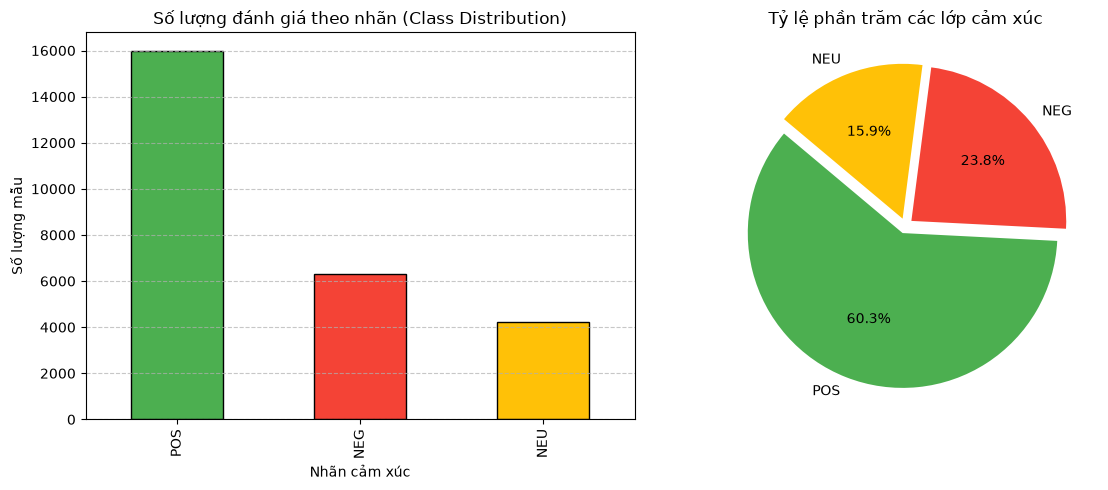

In [4]:
label_counts = df_clean["label"].value_counts()
print("--- PHÂN BỐ NHÃN THỰC TẾ ---")
print(label_counts)
print("\n--- TỶ LỆ PHẦN TRĂM ---")
print((df_clean["label"].value_counts(normalize=True) * 100).round(2))

# Vẽ biểu đồ cột và biểu đồ tròn
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
colors = ["#4CAF50", "#F44336", "#FFC107"]

label_counts.plot(kind="bar", ax=ax[0], color=colors, edgecolor="black")
ax[0].set_title("Số lượng đánh giá theo nhãn (Class Distribution)")
ax[0].set_xlabel("Nhãn cảm xúc")
ax[0].set_ylabel("Số lượng mẫu")
ax[0].grid(axis="y", linestyle="--", alpha=0.7)

ax[1].pie(label_counts, labels=label_counts.index, autopct="%1.1f%%", colors=colors, startangle=140, explode=[0.05, 0.05, 0.05])
ax[1].set_title("Tỷ lệ phần trăm các lớp cảm xúc")
plt.tight_layout()
plt.show()

## 3. Phân tích độ dài câu (Sequence Length Distribution)
Đo lường độ dài câu theo số từ để chọn siêu tham số `max_length` tối ưu cho Bi-LSTM và PhoBERT.

--- THỐNG KÊ ĐỘ DÀI CÂU ---
Độ dài trung bình: 11.02 từ
Độ dài trung vị: 8 từ
95% số câu dài dưới: 29 từ
Câu dài nhất: 74 từ


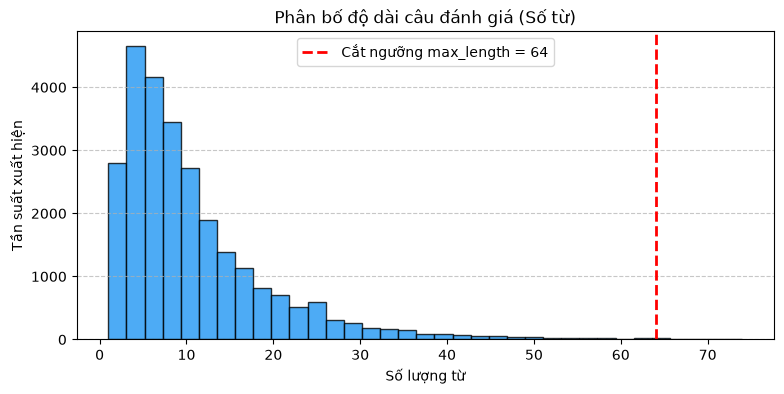

In [5]:
df_clean["word_count"] = df_clean["content"].apply(lambda x: len(str(x).split()))

print("--- THỐNG KÊ ĐỘ DÀI CÂU ---")
print(f"Độ dài trung bình: {df_clean['word_count'].mean():.2f} từ")
print(f"Độ dài trung vị: {df_clean['word_count'].median():.0f} từ")
print(f"95% số câu dài dưới: {np.percentile(df_clean['word_count'], 95):.0f} từ")
print(f"Câu dài nhất: {df_clean['word_count'].max()} từ")

# Vẽ biểu đồ tần suất độ dài
plt.figure(figsize=(9, 4))
plt.hist(df_clean["word_count"], bins=35, color="#2196F3", edgecolor="black", alpha=0.8)
plt.axvline(x=64, color="red", linestyle="--", linewidth=2, label="Cắt ngưỡng max_length = 64")
plt.title("Phân bố độ dài câu đánh giá (Số từ)")
plt.xlabel("Số lượng từ")
plt.ylabel("Tần suất xuất hiện")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

## 4. Luu du lieu da lam sach vao thu muc data/processed/
Luu file shopee_reviews_cleaned.csv de san sang cho Tuan 3.

In [6]:
out_dir = os.path.join('..', 'data', 'processed')
os.makedirs(out_dir, exist_ok=True)
out_file = os.path.join(out_dir, 'shopee_reviews_cleaned.csv')
df_clean[['content', 'label', 'start']].to_csv(out_file, index=False)
print('Da luu thanh cong:')
print('File:', out_file)
print('So dong:', len(df_clean))

Da luu thanh cong:
File: ..\data\processed\shopee_reviews_cleaned.csv
So dong: 26516
